# T21 · Đặt tên cụm và hồ sơ phân khúc đối tác

Ghép nhãn K-Means từ T20 với đặc trưng gốc từ T18, mô tả quy mô, CAGR, cơ cấu HS và các đối tác tiêu biểu. Tên cụm được tạo theo đặc trưng dẫn đầu và CAGR trung bình, không hàm ý tốt/xấu hay tiềm năng. Biểu đồ và PDF dùng house style P03. Xuất hồ sơ một trang A4 ngang tại `data/clean/segment_profile.pdf`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import FuncFormatter

input_names = (
    'partner_features.csv',
    'partner_feature_columns.csv',
    'partner_clusters.csv',
)
root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if all((p / 'data' / 'clean' / name).is_file() for name in input_names)),
    None,
)
if root is None:
    raise FileNotFoundError('Chạy T20 trước và kiểm tra đầu ra T18/T20 tại data/clean/.')

clean = root / 'data' / 'clean'
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from notebooks.house_style.house_style import (
    ANNOTATION, DIVERGING_CMAP, SOURCE, apply_style, declutter,
    diverging_norm, format_number, format_usd,
)
df_raw = pd.read_csv(
    clean / input_names[0],
    dtype={'partner_code': 'string', 'partner_iso3': 'string'},
)
clusters_source = pd.read_csv(
    clean / input_names[2], dtype={'partner_code': 'string'}
)
if 'cluster_method' not in clusters_source.columns or not clusters_source['cluster_method'].str.startswith('KMeans(').all():
    raise ValueError('T20 cần ghi rõ phương pháp K-Means trong partner_clusters.csv.')
df_clusters = clusters_source[['partner_code', 'cluster']]
manifest = pd.read_csv(clean / input_names[1]).sort_values('feature_order')
features = manifest['feature'].tolist()
if (
    'cagr_pct' not in features
    or 'trade_analysis_usd' not in df_raw.columns
    or 'partner_name' not in df_raw.columns
    or df_raw['partner_code'].isna().any()
    or df_raw['partner_code'].duplicated().any()
    or df_clusters['partner_code'].isna().any()
    or df_clusters['partner_code'].duplicated().any()
    or df_clusters['cluster'].isna().any()
    or not set(features).issubset(df_raw.columns)
):
    raise ValueError('Kiểm tra danh tính, cột đặc trưng và nhãn cụm đầu vào.')

df_merged = df_raw.merge(
    df_clusters, on='partner_code', how='left', validate='one_to_one', indicator=True
)
if len(df_merged) != len(df_raw) or df_merged['_merge'].ne('both').any():
    raise ValueError('Có đối tác thiếu nhãn hoặc ghép nhãn làm thay đổi số dòng.')
df_merged = df_merged.drop(columns='_merge')
if not np.isfinite(df_merged[features + ['trade_analysis_usd']].to_numpy(dtype=float)).all():
    raise ValueError('Dữ liệu hồ sơ còn giá trị thiếu hoặc vô hạn.')
print(f'Đầu vào: {len(df_merged)} đối tác, {df_merged["cluster"].nunique()} cụm.')

Đầu vào: 39 đối tác, 4 cụm.


## 1. Tóm tắt và tên mô tả cụm

Cơ cấu HS là trung bình tỷ trọng trong cụm; đối tác tiêu biểu được chọn theo kim ngạch năm phân tích.

In [2]:
hs_cols = [feature for feature in features if feature != 'cagr_pct']
if not hs_cols:
    raise ValueError('Không tìm thấy đặc trưng tỷ trọng HS.')

cluster_summary_rows = []
for cluster_id, group in df_merged.groupby('cluster'):
    hs_means = group[hs_cols].mean().sort_values(ascending=False)
    top3_hs = ', '.join(
        f'{column.replace("_share_pct", "").upper()}: {value:.1f}%'
        for column, value in hs_means.head(3).items()
    )
    top_partners = group.nlargest(3, 'trade_analysis_usd')['partner_name']
    cluster_summary_rows.append({
        'cluster': int(cluster_id),
        'n_partners': len(group),
        'cagr_mean_pct': round(group['cagr_pct'].mean(), 2),
        'cagr_median_pct': round(group['cagr_pct'].median(), 2),
        'trade_2024_total_usd': group['trade_analysis_usd'].sum(),
        'top3_hs_mean': top3_hs,
        'exemplar_partners': ', '.join(top_partners.tolist()),
    })

summary_df = pd.DataFrame(cluster_summary_rows).sort_values('cluster')
cluster_names = {
    0: 'Cơ cấu hỗn hợp công nghiệp nhẹ, dệt may, giày dép và thiết bị điện',
    1: 'Đối tác châu Á và Türkiye, nghiêng về máy móc, kim loại và khoáng sản',
    2: 'CAGR trung bình cao nhất; tỷ trọng máy móc, thiết bị điện nổi bật',
    3: 'Belgium — cụm đơn lẻ, nổi bật ở hóa chất, kim loại và thiết bị chính xác',
}
if set(summary_df['cluster'].astype(int)) != set(cluster_names):
    raise ValueError('Tên mô tả cần được cập nhật khi số cụm thay đổi.')
summary_df['cluster_name'] = summary_df['cluster'].map(cluster_names)

print('Tóm tắt các cụm trên dữ liệu gốc:')
print(summary_df[[
    'cluster', 'cluster_name', 'n_partners', 'cagr_mean_pct',
    'cagr_median_pct', 'trade_2024_total_usd', 'top3_hs_mean',
    'exemplar_partners',
]].to_string(index=False))

Tóm tắt các cụm trên dữ liệu gốc:
 cluster                                                             cluster_name  n_partners  cagr_mean_pct  cagr_median_pct  trade_2024_total_usd                                top3_hs_mean                          exemplar_partners
       0       Cơ cấu hỗn hợp công nghiệp nhẹ, dệt may, giày dép và thiết bị điện          20           7.39             6.82          3.066157e+11  HS_XVI: 39.1%, HS_XI: 11.7%, HS_XII: 10.9%                        USA, Japan, Germany
       1    Đối tác châu Á và Türkiye, nghiêng về máy móc, kim loại và khoáng sản           6           8.13             8.21          9.799441e+10      HS_XVI: 37.8%, HS_XV: 9.8%, HS_V: 8.3%              Singapore, Thailand, Malaysia
       2        CAGR trung bình cao nhất; tỷ trọng máy móc, thiết bị điện nổi bật          12          11.83            11.13          4.332744e+11     HS_XVI: 50.4%, HS_II: 14.3%, HS_V: 5.9% China, Rep. of Korea, China, Hong Kong SAR
       3 Belgium — cụm đơn

## 2. Heatmap

Màu heatmap biểu thị z-score giữa các cụm theo từng đặc trưng; PDF cũng ghi rõ giới hạn diễn giải.

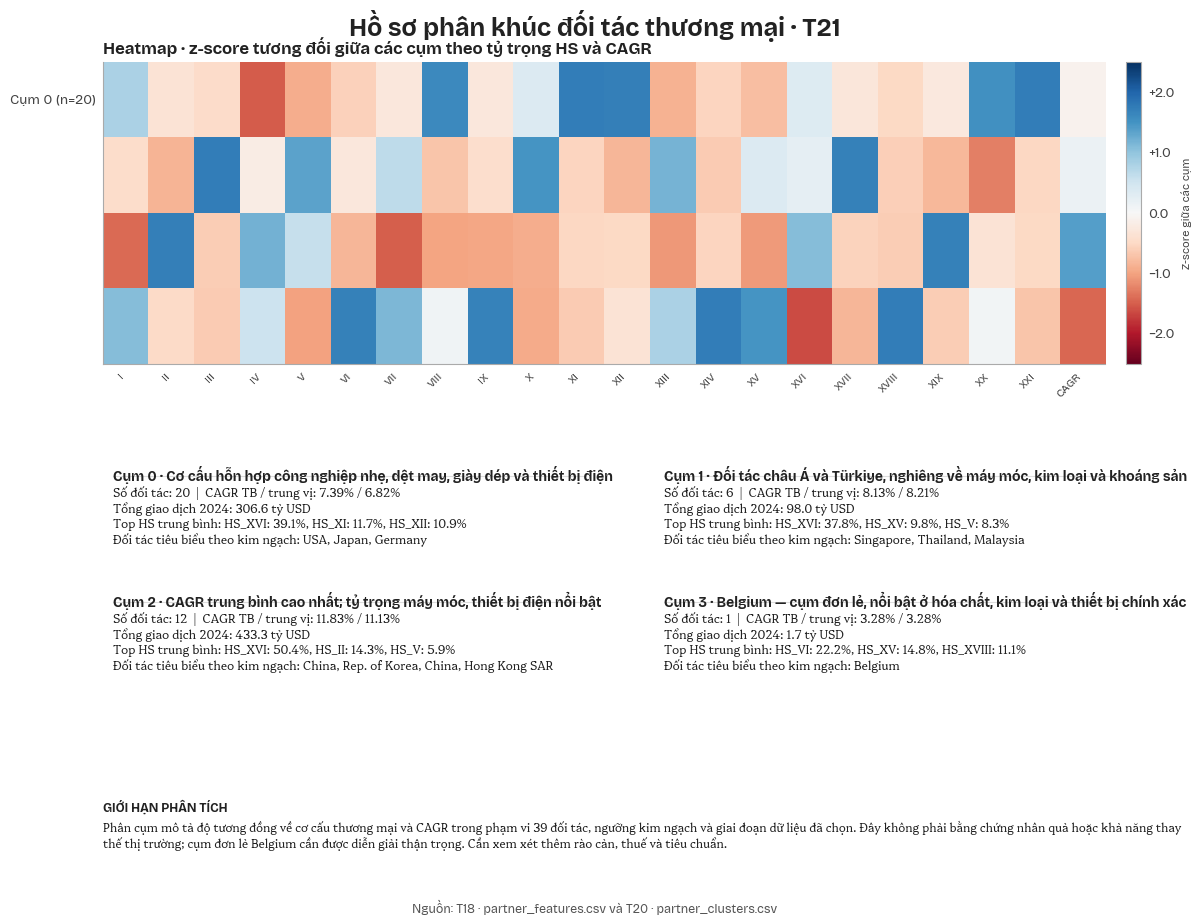

Đã xuất hồ sơ phân khúc tới: C:\Trực quan hóa dữ liệu\NOBEL-V-T-L---TR-C-QUAN-HO-D-LI-U-main\data\clean\segment_profile.pdf
Dung lượng PDF: 134,694 bytes


In [3]:
cluster_means = df_merged.groupby('cluster')[features].mean().sort_index()
cluster_std = cluster_means.std(axis=0, ddof=0).replace(0, 1)
cluster_z = (cluster_means - cluster_means.mean(axis=0)) / cluster_std
out_path = clean / 'segment_profile.pdf'
limit_text = (
    'Phân cụm mô tả độ tương đồng về cơ cấu thương mại và CAGR trong phạm vi '
    '39 đối tác, ngưỡng kim ngạch và giai đoạn dữ liệu đã chọn. Đây không phải '
    'bằng chứng nhân quả hoặc khả năng thay thế thị trường; cụm đơn lẻ Belgium '
    'cần được diễn giải thận trọng. Cần xem xét thêm rào cản, thuế và tiêu chuẩn.'
)

with apply_style(), PdfPages(out_path) as pdf:
    fig = plt.figure(figsize=(12, 9.5))
    grid = fig.add_gridspec(
        3, 1, height_ratios=[1.35, 1.05, 0.32], hspace=0.48,
        left=0.09, right=0.96, top=0.92, bottom=0.075,
    )
    fig.suptitle(
        'Hồ sơ phân khúc đối tác thương mại · T21',
        y=0.975, fontweight='bold',
    )

    ax_hm = fig.add_subplot(grid[0])
    image = ax_hm.imshow(
        cluster_z.values, aspect='auto', cmap=DIVERGING_CMAP,
        norm=diverging_norm(-2.5, 2.5),
    )
    ax_hm.set_yticks(range(len(cluster_means.index)))
    ax_hm.set_yticklabels([
        f'Cụm {int(cluster_id)} (n={int(summary_df.loc[summary_df["cluster"] == cluster_id, "n_partners"].iloc[0])})'
        for cluster_id in cluster_means.index
    ])
    ax_hm.set_xticks(range(len(features)))
    ax_hm.set_xticklabels([
        'CAGR' if feature == 'cagr_pct' else feature.split('_')[1].upper()
        for feature in features
    ], rotation=45, ha='right', fontsize=8)
    ax_hm.set_title(
        'Heatmap · z-score tương đối giữa các cụm theo tỷ trọng HS và CAGR',
        fontsize=12, loc='left',
    )
    colorbar = fig.colorbar(image, ax=ax_hm, fraction=0.02, pad=0.02)
    colorbar.set_label('Z-score giữa các cụm', fontsize=8)
    colorbar.ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: format_number(value, 1, signed=True))
    )
    declutter(ax_hm)

    cards = grid[1].subgridspec(2, 2, wspace=0.12, hspace=0.16)
    for ax, (_, row) in zip(
        (fig.add_subplot(cards[i, j]) for i in range(2) for j in range(2)),
        summary_df.iterrows(),
    ):
        ax.set_axis_off()
        cluster_id = int(row['cluster'])
        ax.text(
            0.02, 0.96, f'Cụm {cluster_id} · {cluster_names[cluster_id]}',
            transform=ax.transAxes, va='top', ha='left',
            fontsize=10, fontweight='bold', wrap=True,
        )
        details = (
            f'Số đối tác: {row["n_partners"]}  |  '
            f'CAGR TB / trung vị: {row["cagr_mean_pct"]:.2f}% / '
            f'{row["cagr_median_pct"]:.2f}%\n'
            f'Tổng giao dịch 2024: {format_usd(row["trade_2024_total_usd"])}\n'
            f'Top HS trung bình: {row["top3_hs_mean"]}\n'
            f'Đối tác tiêu biểu theo kim ngạch: {row["exemplar_partners"]}'
        )
        ax.text(
            0.02, 0.77, details, transform=ax.transAxes,
            fontsize=8.5, wrap=True,
            **(ANNOTATION | {'ha': 'left', 'va': 'top'}),
        )
        ax.axhline(0.86, color='#DDDDDD', linewidth=0.8, xmin=0.02, xmax=0.98)

    ax_limit = fig.add_subplot(grid[2])
    ax_limit.set_axis_off()
    ax_limit.text(
        0.0, 0.92, 'GIỚI HẠN PHÂN TÍCH', transform=ax_limit.transAxes,
        va='top', ha='left', fontsize=9, fontweight='bold',
    )
    ax_limit.text(
        0.0, 0.62, limit_text, transform=ax_limit.transAxes,
        wrap=True, **(ANNOTATION | {'ha': 'left', 'va': 'top', 'fontsize': 8.3}),
    )
    fig.text(0.5, 0.025, 'Nguồn: T18 · partner_features.csv và T20 · partner_clusters.csv', **SOURCE)
    pdf.savefig(fig)
    display(fig)
    plt.close(fig)

if not out_path.is_file() or out_path.stat().st_size == 0:
    raise RuntimeError(f'Không tạo được hồ sơ PDF: {out_path}')
print(f'Đã xuất hồ sơ phân khúc tới: {out_path}')
print(f'Dung lượng PDF: {out_path.stat().st_size:,} bytes')